# 01 · 同一份历史位置名单，为什么取 K/V 的写法能相差 25 倍？

本课包含两个阶段的已保存实验：**G0 是本机基础操作测量**，测索引打分、选位、K/V 取行等操作；**G1a 是单层注意力对照**，测这些操作连起来后，与完整读取相比要多少时间。编号仅用于对应项目记录。

本课 **A** 表示完整注意力，**D** 表示先用索引器选历史位置，再对入选的 K/V 做主注意力。这里 D 的参数还没有训练，只检查执行成本；第四课以后才用 D0/D 区分训练前后。

三个问题依次是：

1. **同一份位置名单，为什么两种 K/V 取行写法相差 25 倍？**
2. **主注意力只取约 3.3% 的历史位置，为什么总耗时不一定下降？**
3. **为什么分段时间之和不能替代整条读取路径的时间？**

真实测速条件是 Mac M4 Max / PyTorch MPS。默认执行只读保存结果、展示源码、运行 CPU 小例子，不重新测速或训练。

## 0. 加载结果与源码版本

G0/G1a 的运行清单保留数据、配置与源码指纹；下面核对当前文件与历史文件。理解取行机制可以直接读第 1 节，运行 Notebook 时仍需先执行这些加载单元。

In [1]:
from pathlib import Path
import hashlib, inspect, json, sys

root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / ".attention_lab_bootstrap").is_file()), None)
assert root is not None, "请从 attention-lab 项目目录或 notebooks 子目录打开本页"
sys.path.insert(0, str(root / "src"))
import attention_lab
from attention_lab import sparse, decode, selection

g0 = json.loads((root / "reports/g0_probe_mac_m4max.json").read_text())
g1a = json.loads((root / "reports/g1a_summary_mac_m4max.json").read_text())
g1a_manifest = json.loads((root / "reports/g1a_manifest_mac_m4max.json").read_text())
roof = json.loads((root / "reports/g0_roofline_mac_bw390.json").read_text())
print("G0 run:", g0["run_id"], "| torch", g0["software"]["torch"], "|", g0["host"]["chip"], g0["host"]["gpu_cores"], "核 GPU")
print("G1a runs:", ", ".join(g1a["runs"]))

G0 run: g0-mac-20261016T131252Z | torch 2.14.1 | Apple M4 Max 40 核 GPU
G1a runs: g1a-mac-20261016T145200Z-p1, g1a-mac-20261016T145616Z-p2, g1a-mac-20261016T150105Z-p3, g1a-mac-20261016T150606Z-p4, g1a-mac-20261016T151108Z-p5, g1a-mac-20261016T151610Z-compile


In [2]:
# 当前源码 vs 跑分时记录的哈希（manifest 中的 source_hashes）
sha = lambda p: hashlib.sha256(p.read_bytes()).hexdigest()
recorded = g1a_manifest["runs"][0]["source_hashes"]
rows = []
for rel in sorted(recorded):
    now = sha(root / rel)
    rows.append((rel, recorded[rel][:12], now[:12], "一致" if now == recorded[rel] else "不同"))
w = max(len(r[0]) for r in rows)
for r in rows:
    print(f"{r[0]:<{w}}  跑分时 {r[1]}  当前 {r[2]}  {r[3]}")
snap = root / "reports/provenance/microbench_at_formal_runs.py"
print("\n跑分时的 bench/microbench.py 快照哈希:", sha(snap)[:12], "→ 与 manifest", "一致" if sha(snap) == recorded["bench/microbench.py"] else "不同")
print("快照与当前文件的差异行数:", sum(1 for l in (root / "reports/provenance/microbench_post_run_edit.diff").read_text().splitlines() if l[:1] in "+-" and not l.startswith(("+++", "---"))))

bench/microbench.py             跑分时 4c1e5b66d998  当前 69216b81d705  不同
src/attention_lab/__init__.py   跑分时 e8257adc5a4c  当前 a3caef5cc422  不同
src/attention_lab/decode.py     跑分时 f0dde0182b1c  当前 ded8ef3c1c92  不同
src/attention_lab/full.py       跑分时 b3b0f6c8cce5  当前 b3b0f6c8cce5  一致
src/attention_lab/indexer.py    跑分时 911db9e5af2b  当前 911db9e5af2b  一致
src/attention_lab/reference.py  跑分时 bdd13df4ed5c  当前 bdd13df4ed5c  一致
src/attention_lab/runinfo.py    跑分时 3d1d4cfbcbf5  当前 9d38b853cf6b  不同
src/attention_lab/selection.py  跑分时 a0dbe7aa0f0b  当前 a0dbe7aa0f0b  一致
src/attention_lab/sparse.py     跑分时 bbe8805b45a4  当前 bbe8805b45a4  一致

跑分时的 bench/microbench.py 快照哈希: 4c1e5b66d998 → 与 manifest 一致
快照与当前文件的差异行数: 2


当前源码后来有过修改，旧测量对应的源码和修改记录保留在 `reports/provenance/`。上表用于核对版本，不改变旧结果；“不同”需要对照快照，不能靠改写旧清单消除。下文展示的读取函数与历史测速的对应关系由这些记录约束。

## 1. 问题一：按同一份位置名单取出历史 K/V，为什么两种写法相差 25 倍？

**具体取的是什么？** 以 32K 档为例，一套 K、一套 V 的形状各是 `[8, 32768, 128]`：8 个 KV 组，每组有 32768 个历史位置，每个位置保存一个 128 维向量。本节给每组一份含 1024 个位置的名单 `I[g]`，取出这些位置的**完整 K 行和 V 行**：

```python
K_sub[g, t, :] = K[g, I[g, t], :]
V_sub[g, t, :] = V[g, I[g, t], :]
# K_sub、V_sub 各为 [8, 1024, 128]
```

因此这里的“子集”是按历史位置选出的 K/V 行。两种写法使用同一份输入、同一份名单，输出形状和值相同；比较的是怎样把这些行取出来。

**名单已经在计时前算好。** 基准用随机生成的索引特征给出 `I`，各组名单可不同；三种取行实现、36 套 K/V 都复用这份 `I`。这一项耗时只包含取 K 和取 V，不含索引打分、top-k 或主注意力。本节名额为 `k=N/32=1024`，还没有加入第 2 节的首部/近期固定位置。

**为何做这组对照？** G0 起初只测“按名单取 K/V 行”的成本，结果慢于预想，才追加不同写法。运行前预测及事后对照保存在项目称作“预测卡片”的文件中；25 倍差距是原预测未列出的发现。

下面是 G1a 采用的取行函数。它把 `[B,G,C,d]` 看成 `[B*G*C,d]`，把每组的原位置换成 `g*C+j` 行号后使用 `index_select`。这里 B 是 batch，G 是 KV 组数，C 是每组缓存容量，d 是头维度，S 是入选数；**它们是数组轴，不是后续课程的方法代号**。

In [3]:
print(inspect.getsource(sparse.flatten_cache))
print(inspect.getsource(sparse.row_offsets))
print(inspect.getsource(sparse.gather_rows))

def flatten_cache(x: torch.Tensor) -> torch.Tensor:
    """[B,G,C,d] contiguous -> [B*G*C, d] view. No copy; raises instead of copying silently."""
    if x.dim() != 4:
        raise ValueError(f"cache must be [B,G,C,d], got {tuple(x.shape)}")
    if not x.is_contiguous():
        raise ValueError("cache must be contiguous so the flattened view is free")
    B, G, C, d = x.shape
    return x.view(B * G * C, d)

def row_offsets(batch: int, groups: int, capacity: int, device) -> torch.Tensor:
    """[B,G,1] int64 offsets that turn a position into a row id of the flattened cache."""
    return (torch.arange(batch * groups, device=device, dtype=torch.long) * capacity).view(batch, groups, 1)

def gather_rows(x: torch.Tensor, selected: torch.Tensor, offsets=None) -> torch.Tensor:
    """x [B,G,C,d], selected [B,G,S] original positions -> [B,G,S,d]; row s of group (b,g) is x[b,g,selected[b,g,s]]."""
    B, G, C, d = x.shape
    if selected.shape[:2] != (B, G) or selected.dim() != 3:
        r

**CPU 缩小例子。** 下面用 `[1,2,16,4]` 的 K 和每组 8 个位置的名单，对照三种实现：拉平后的 `index_select`、`torch.gather`、高级索引。实际测速对 K、V 各做一次同样的取行；本格只需用 K 核对位置映射和输出一致性。

In [4]:
import torch
torch.manual_seed(0)
B, G, C, d = 1, 2, 16, 4
k = torch.randn(B, G, C, d)
selected = torch.tensor([[[0, 1, 2, 3, 9, 13, 14, 15], [0, 1, 2, 3, 5, 11, 14, 15]]])   # [B,G,S]：本例直接给定的原始位置名单
S = selected.shape[-1]

a = sparse.gather_rows(k, selected)                                      # (a) 拉平 + index_select：G1a 的写法
expanded = selected[..., None].expand(B, G, S, d)                        # (b) torch.gather 需要和输出同形状的下标
b = torch.gather(k, 2, expanded)
gi = torch.arange(G).view(1, G, 1).expand(B, G, S)                       # (c) 高级索引
c = k[torch.arange(B).view(B, 1, 1), gi, selected]

print("三种写法结果相同:", torch.equal(a, b) and torch.equal(a, c))
print("输出形状:", tuple(a.shape), "= [B, G, S, d]")
print("(a) 行号张量:", tuple((selected + sparse.row_offsets(B, G, C, k.device)).reshape(-1).shape), "个 int64 →", S * G * 8, "字节")
print("(b) 展开下标:", tuple(expanded.shape), "个 int64 → 若物化为连续张量", S * G * d * 8, "字节（是 (a) 的 d 倍）")
print("取出的 K 字节:", a.numel() * a.element_size())

三种写法结果相同: True
输出形状: (1, 2, 8, 4) = [B, G, S, d]
(a) 行号张量: (16,) 个 int64 → 128 字节
(b) 展开下标: (1, 2, 8, 4) 个 int64 → 若物化为连续张量 512 字节（是 (a) 的 d 倍）
取出的 K 字节: 256


**这里的“36 层轮换”究竟怎样计时？** 基准预先独立分配 36 套同形状的 K/V 数组，记为 `K[0],V[0]` 到 `K[35],V[35]`。这 36 次取行之间没有 Transformer 层间依赖，前一次输出不会送给下一次；“层”只是基准把一套数组记作一层的简称。

```python
# I 在计时前给定，各方法使用同一份名单
for layer in range(36):
    take_rows(K[layer], I)
    take_rows(V[layer], I)
# 测完整循环：预热 2 轮，计量 8 轮，每轮前后同步
per_layer_us = median(pass_seconds) / 36 * 1e6
```

对 32K / bf16，每套 K+V 占 128 MiB，36 套合计 4.5 GiB；一次只取其中 4 MiB 的 K/V 行。一轮依次访问第 0、1、…、35 套，下一轮才再次访问第 0 套。这样拉开了同一内存地址被再次访问的间隔。后续 G1a 的 `hot` 对照使用 `0→0→…→0` 共 36 次，而 `rotating` 使用 `0→1→…→35`；本节 G0 的取行表只有后一种访问方式。

这里要区分**保存模型历史的 K/V 数组**和 **GPU 硬件缓存**：改变数组访问顺序，是为了检查反复读取同一地址带来的硬件缓存复用。没有测硬件缓存命中率，因此“轮换”不保证每次都从主存读取。`rotating` 就是上面这个访问顺序，不是模型在生成 36 个 token。

**G0 取行实测如下**，bf16，单位为上述每套 K/V 的微秒。N 是每组历史位置数，k 是每组取出的行数。最后一列是完整 K 表的 QK 扫描参照，不包含取 V。

In [5]:
ipc = g0["probes"]["index_path_cost"]
print(f"{'N':>6} {'k':>5} | {'gather 展开下标':>14} {'index_select 拉平':>16} {'高级索引':>8} | {'gather/index_select':>18} | {'整层 K 扫描(q·Kᵀ)':>16}")
scan_us = g0["probes"]["attention_scan_qk"]["rotating_workset"]["us_per_layer"]
for N in (8192, 16384, 32768):
    v = ipc[f"N{N}"]
    print(f"{N:>6} {v['k']:>5} | {v['gather_kv_us_per_layer']:>14.0f} {v['gather_index_select_flat_us_per_layer']:>16.0f} {v['gather_adv_index_us_per_layer']:>8.0f} | "
          f"{v['gather_kv_us_per_layer']/v['gather_index_select_flat_us_per_layer']:>18.0f}x | {(f'{scan_us:.0f}' if N == 32768 else '未测'):>16}")
print("\n（整层 K 扫描只在 32K 测过；它读 64 MiB，index_select 只读", ipc["N32768"]["selected_kv_bytes_per_layer"] // 2 // 2**20, "MiB 的 K。）")

     N     k |    gather 展开下标  index_select 拉平     高级索引 | gather/index_select |    整层 K 扫描(q·Kᵀ)
  8192   256 |            187               16       52 |                 12x |               未测
 16384   512 |            333               21       81 |                 16x |               未测
 32768  1024 |            673               27      154 |                 25x |              172

（整层 K 扫描只在 32K 测过；它读 64 MiB，index_select 只读 2 MiB 的 K。）


三种实现的输入、名单和输出相同；32K 档 `torch.gather` 为 673 µs，拉平 `index_select` 为 27 µs，约相差 25 倍。

实现差别就在上面的代码：`gather` 接收 `[G,k,d]` 的展开下标，`index_select` 接收 `G*k` 个完整行号。`expand` 本身不分配那份完整下标数组；现有记录也没有证明后端是否将其物化、贡献多少耗时，不能把这一猜测当成 25 倍差距的已定位原因。

后续单层实验因此使用实测较快的 `index_select` 路径。这个选择由当前 PyTorch/MPS 的测量支持，不把它升级为其他后端或所有 gather 实现的结论。

## 2. 问题二：只取约 3.3% 的历史位置，为什么总耗时不一定下降？

这一节开始计量**完整的 D 读取链**，表中记作 **D_full**：本步索引追加、查询投影、候选打分、top-k、合并名单、取 K/V、子集主注意力全部计时。名字里的 full 指链路成本齐全，不是读取全历史。

本实验的固定规则是：**F 保留首 4 和最近 64 个合法位置**，重叠去重；剩余 M 个位置为候选域。请求起始长度 N0 决定 `k0=min(round(ρ*N0), 起始候选数)`，之后 k0 固定，本步 k 不超过当前候选数；总读取数 `S=|F|+k`。因此 ρ=1/32 不等于总读取比例。在本节 32K 档，S=68+1024=1092，区别于上一节纯取行探针的 1024 行。

索引器把组内查询投影为 r 维的 u，把各历史键投影为 r 维的 z，`zT` 是按 `[B,G,r,C]` 保存的索引键表。索引使用位置旋转前的 `q_pre/k_pre`，主注意力使用 `q_main/k_cache`；名单仍是原位置。函数形状里的 h 是每组查询头数，T 是本次查询数，这里 T=1。

**运行前预测。** G0 用 A 的理想读取时间减去当时实测的索引链成本，得到 8K 持平偏负、16K 持平偏正、32K 正收益；同时预测 D 有一部分不随历史长度显著改变的固定成本。下面把 D 的全部步骤算进去检查。

In [6]:
print(inspect.getsource(decode.sparse_decode_step_kernel))
print(inspect.getsource(decode.select_rows_kernel))

def sparse_decode_step_kernel(q_main, q_pre, k_cache, v_cache, zT, wq_t_scaled, wk, fixed_rows, off_lo, lo: int,
                              hi: int, k: int, selected_count: int, *, k_pre_new=None, write_col: int = -1,
                              scale=None, backend="sdpa", return_rows: bool = False, canonical_order: bool = False):
    """One layer's D read for one new query (T == 1). Every D-only cost is inside this function.

    `return_rows=True` also returns the flat row ids that were read (for selection diagnostics); the device work is the
    same either way.
    """
    B, G, h, T, d = q_main.shape
    if T != 1:
        raise ValueError("a decode step takes exactly one new query position")
    if k_pre_new is not None:
        zT[..., write_col:write_col + 1].copy_(project_keys(k_pre_new, wk))   # z of the newest key, its own column
    u = project_queries(q_pre, wq_t_scaled)                                     # [B,G,1,r]
    rows = select_rows_kernel(u, zT, fixed_rows, o

**本节具体形状。** G=8 个 KV 组，主头维度 d=128，索引维度 r=32，N=32768，ρ=1/32。下一格列出固定位置、候选范围、入选数与打分形状。

In [7]:
from attention_lab import prepare_request
req = prepare_request(1, 8, 32768, valid_length=32768, query_position=32767, rho=1/32, device="cpu")
lay = req.layout
print(f"合法位置 {lay.legal_length}；固定集合 F = 首 {lay.fixed_prefix} + 近 {lay.legal_length - lay.recent_start} = {lay.fixed_count}；候选域 [{lay.candidate_lo}, {lay.candidate_hi}) 共 {lay.candidate_count}")
print(f"k0 = min(round(ρN), |候选|) = {req.k0}；本步 k = {req.k}；读取数 S = F + k = {req.selected_count}，占 N 的 {100*req.selected_count/32768:.1f}%")
print("索引打分形状 u [1,8,1,32] × zT[..., lo:hi] [1,8,32,", lay.candidate_count, "] → 分数 [1,8,1,", lay.candidate_count, "]")
print("top-k 下标 [1,8,", req.k, "] → 行号 [", 8 * req.selected_count, "] → K/V 子集 [1,8,", req.selected_count, ",128]")

合法位置 32768；固定集合 F = 首 4 + 近 64 = 68；候选域 [4, 32704) 共 32700
k0 = min(round(ρN), |候选|) = 1024；本步 k = 1024；读取数 S = F + k = 1092，占 N 的 3.3%
索引打分形状 u [1,8,1,32] × zT[..., lo:hi] [1,8,32, 32700 ] → 分数 [1,8,1, 32700 ]
top-k 下标 [1,8, 1024 ] → 行号 [ 8736 ] → K/V 子集 [1,8, 1092 ,128]


**G1a 单层对照结果。** bf16、eager、36 套数据依次访问。G1a 在每套数据上运行完整 A 或 D_full，一轮耗时仍除以 36；表中进一步取六次独立进程测量的中位数。每套的查询、K/V 与索引参数预先生成，前一套输出不作为后一套输入。

A 是该条件下选出的最快合法完整注意力实现。D_full/A 小于 1 表示 D 更快。“D 索引+KV MiB”包含扫描候选索引表及读取入选 K/V 的字节账，不是实测内存流量。

In [8]:
agg = g1a["aggregate"]
def get(dtype, N, rho, strat, mode="eager", workset="rotating"):
    for key, v in agg.items():
        p = key.split("|")
        if p[0] == dtype and p[1] == mode and p[2] == workset and int(p[3]) == N and abs(float(p[4]) - rho) < 1e-9 and p[5] == strat and p[7] == str(N):
            return v
    return None

print(f"{'N':>6} {'ρ':>5} | {'A µs':>7} {'D_full µs':>10} {'D_full/A':>9} | {'A 读 KV MiB':>11} {'D 索引+KV MiB':>13} {'字节比':>7}")
for N in (8192, 16384, 32768):
    for rho in (1/32, 1/8):
        A, D = get("bfloat16", N, rho, "A"), get("bfloat16", N, rho, "D_full")
        cell = D["cell"]
        a_mib = cell["kv_bytes_per_layer"] / 2**20
        d_mib = (cell["selected_count"] * cell["kv_bytes_per_layer"] / N + cell["index_bytes_per_layer"] * cell["candidate_count"] / N) / 2**20
        print(f"{N:>6} 1/{round(1/rho):<3} | {A['median']:>7.0f} {D['median']:>10.0f} {D['median']/A['median']:>9.2f} | {a_mib:>11.0f} {d_mib:>11.1f} {d_mib/a_mib:>7.2f}")

     N     ρ |    A µs  D_full µs  D_full/A |  A 读 KV MiB   D 索引+KV MiB     字节比
  8192 1/32  |     110        195      1.78 |          32         5.2    0.16
  8192 1/8   |     100        216      2.17 |          32         8.2    0.26
 16384 1/32  |     203        222      1.10 |          64        10.2    0.16
 16384 1/8   |     192        260      1.36 |          64        16.2    0.25
 32768 1/32  |     405        297      0.73 |         128        20.2    0.16
 32768 1/8   |     404        411      1.02 |         128        32.2    0.25


把 D 拆开看（各段单独计时，bf16，ρ=1/32）。注意哪些段随 N 增长，哪些不随 N 变：

日志段名对应：`z_append` 追加本步索引键；`u_proj` 查询投影；`score_candidates` 候选打分；`topk` 选位；`merge_rows` 合并 F 与候选；`gather_k/gather_v` 取 K/V；`subset_attention` 子集主注意力。

In [9]:
comps = ["comp:z_append", "comp:u_proj", "comp:score_candidates", "comp:topk", "comp:merge_rows", "comp:gather_k", "comp:gather_v", "comp:subset_attention"]
print(f"{'段':<24}" + "".join(f"{N:>9}" for N in (8192, 16384, 32768)))
for c in comps:
    vals = [get("bfloat16", N, 1/32, c) for N in (8192, 16384, 32768)]
    print(f"{c.split(':')[1]:<24}" + "".join(f"{v['median']:>9.1f}" if v else f"{'—':>9}" for v in vals))
print(f"{'分段之和':<24}" + "".join(f"{sum(get('bfloat16', N, 1/32, c)['median'] for c in comps):>9.1f}" for N in (8192, 16384, 32768)))
print(f"{'D_full 链式':<24}" + "".join(f"{get('bfloat16', N, 1/32, 'D_full')['median']:>9.1f}" for N in (8192, 16384, 32768)))
print(f"{'A':<24}" + "".join(f"{get('bfloat16', N, 1/32, 'A')['median']:>9.1f}" for N in (8192, 16384, 32768)))

段                            8192    16384    32768
z_append                     27.1     28.2     27.9
u_proj                       24.6     25.1     24.5
score_candidates             36.1     45.1     60.9
topk                         48.4     53.6     70.8
merge_rows                   13.1     13.0     13.5
gather_k                     10.1     11.9     15.1
gather_v                     10.3     11.8     15.1
subset_attention             13.9     15.9     30.1
分段之和                        183.7    204.5    258.0
D_full 链式                   195.3    222.4    296.5
A                           109.6    202.9    405.3


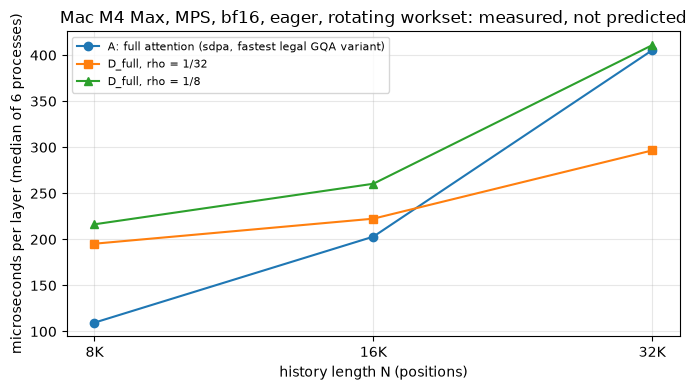

In [10]:
import matplotlib
import matplotlib.pyplot as plt
Ns = [8192, 16384, 32768]
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(Ns, [get("bfloat16", N, 1/32, "A")["median"] for N in Ns], "o-", label="A: full attention (sdpa, fastest legal GQA variant)")
ax.plot(Ns, [get("bfloat16", N, 1/32, "D_full")["median"] for N in Ns], "s-", label="D_full, rho = 1/32")
ax.plot(Ns, [get("bfloat16", N, 1/8, "D_full")["median"] for N in Ns], "^-", label="D_full, rho = 1/8")
ax.set_xscale("log", base=2); ax.set_xticks(Ns); ax.set_xticklabels(["8K", "16K", "32K"])
ax.set_xlabel("history length N (positions)"); ax.set_ylabel("microseconds per layer (median of 6 processes)")
ax.set_title("Mac M4 Max, MPS, bf16, eager, rotating workset: measured, not predicted")
ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**检查。** 字节比与时间比是两条不同的曲线，而字节比本身要分两个口径说。32K、ρ=1/32 时，主注意力只读 1,092 个位置，占 3.3%，入选 K/V 约 4.3 MiB；但为了决定读谁，索引器还要扫描 32,700 个候选位置的索引键，约 16 MiB。按“索引键读一次加入选 K/V 读一次”的载荷模型，上表的字节比是 0.16，不是 4%。时间比是 0.74。8K 时字节比同样是 0.16，时间比却是 1.78。**名单很短，不等于得到名单很便宜：获得名单本身也要读取信息。** 16% 仍是载荷账本，不是实测的内存总流量。

**解释。** A 的时间随 N 线性增长（bf16 约 330 GB/s 的有效读取），D 的时间由一条 8 个算子的链决定，其中 top-k、打分随 N 缓慢增长，其余几乎与 N 无关，所以 D 有一个约 180 到 300 µs 的固定底。两条曲线在 ρ=1/32 时于 16K 与 32K 之间交叉。**"少读"只在 A 本身足够贵的时候才换得到时间。** ρ=1/8 时读取数是 1/32 的 3.8 倍，gather 与子集注意力各多约 40 µs，32K 处 D_full 与 A 持平。

**反例与边界。** “读取字节比例不等于时间比例”在这里以两种方式出现：索引键字节只有 K 的 1/4，打分时间却与扫整层 K 相当；含索引扫描的读取载荷约 16%（入选位置只占 3.3%），时间却是 74%。这些是单层读取阶段的数字，不是整模型每步时间；整模型里还有权重读取、FFN 等，稀疏注意力只能影响其中注意力的一份。没有模型、没有任务、没有质量结论：这个索引器是随机初始化的，它**没有学会**找重要信息，本页只回答"筛选路径的计算成本有没有空间"。

## 3. 问题三：各段单独计时相加，为什么不等于完整执行

**运行前的预测。** G1a 卡片预测"分段之和高于链式 20% 到 30%"，理由是分段计时里每个算子独立提交，链式执行可以让提交与执行重叠。**预测错了方向**：链式比分段之和更慢，8K 多 6%，32K、ρ=1/8 多 28%。

**观察。**

In [11]:
print(f"{'dtype':<9}{'N':>7}{'ρ':>6} | {'分段之和':>9} {'D_full 链式':>12} {'链式/之和':>9}")
for dtype in ("bfloat16", "float32"):
    for N in (8192, 16384, 32768):
        for rho in (1/32, 1/8):
            vals = [get(dtype, N, rho, c) for c in comps]
            D = get(dtype, N, rho, "D_full")
            if all(vals) and D:
                s = sum(v["median"] for v in vals)
                print(f"{dtype:<9}{N:>7} 1/{round(1/rho):<3} | {s:>9.1f} {D['median']:>12.1f} {D['median']/s:>9.2f}")

dtype          N     ρ |      分段之和    D_full 链式     链式/之和
bfloat16    8192 1/32  |     183.7        195.3      1.06
bfloat16    8192 1/8   |     209.9        216.4      1.03
bfloat16   16384 1/32  |     204.5        222.4      1.09
bfloat16   16384 1/8   |     251.9        260.4      1.03
bfloat16   32768 1/32  |     258.0        296.5      1.15
bfloat16   32768 1/8   |     320.4        410.8      1.28
float32     8192 1/32  |     188.5        203.4      1.08
float32     8192 1/8   |     230.4        230.9      1.00
float32    16384 1/32  |     233.3        267.6      1.15
float32    16384 1/8   |     293.6        414.7      1.41
float32    32768 1/32  |     346.7        433.0      1.25
float32    32768 1/8   |     500.2        606.0      1.21


**分段实验到底测了什么？** 看跑分时那份基准源码（归档的快照）里分段的定义：

In [12]:
snap_lines = snap.read_text().splitlines()
start = next(i for i, l in enumerate(snap_lines) if '"comp:z_append"' in l)
print("\n".join(snap_lines[start - 1:start + 8]))

                    comps = {
                        "comp:z_append": lambda i: ls.zT[i][..., N - 1:N].copy_(project_keys(ls.k_pre_new[i], ls.idx[i].wk)),
                        "comp:u_proj": lambda i: project_queries(ls.q_pre[i], ls.idx[i].wq_t_scaled),
                        "comp:score_candidates": lambda i: candidate_scores(u0, ls.zT[i], lo, hi),
                        "comp:topk": lambda i: torch.topk(s0, kk, dim=-1),
                        "comp:merge_rows": lambda i: torch.cat([req.fixed_rows, top0 + req.off_lo], dim=-1).view(-1),
                        "comp:gather_k": lambda i: flatten_cache(ls.K[i]).index_select(0, rows0),
                        "comp:gather_v": lambda i: flatten_cache(ls.V[i]).index_select(0, rows0),
                        "comp:subset_attention": lambda i: subset_attention(ls.q_main[i], ksub0, vsub0),


**解释，以及这次评审纠正了什么。** 分段实验中，top-k 反复用同一份预先算好的分数 `s0`，合并用同一份 `top0`，取行用同一份 `rows0`，子集注意力用同一份 `ksub0/vsub0`；完整链则在链中产生并消费本层新的中间量。因此两者的差不只是"串起来"：数据依赖、临时张量的分配与释放、缓存状态、提交方式都一起变了。

G1a 卡片的第一稿把这个差值写成"MPS 上依赖链没有提交与执行的重叠"。PR #1 的评审指出：现有剖析只开了 CPU 活动，没有 GPU 时间线，这个因果说得太满。修订后的表述是：**已观察到完整链式执行慢于各段独立测量之和；现有证据尚不能分离依赖、缓存、分配与提交方式各自的贡献。** 要归因，需要 MPS signpost 配合 Instruments 看时间线，而那种诊断会改变性能，必须与正式测速分开。

**它对下一阶段真实模型接入与整步测速（G1b，第二课）的要求。** 整模型里的 D 必须按完整链计时，不能把分段数相加当成链式成本；也不要把"链比分段慢"当作已经解释过的 MPS 特性去推断别的平台。

## 4. 预测与观察：两个实验阶段的对照账

把运行前写下的预测与运行后的结果放在一起，是这个项目要求自己的纪律。下面是 G1a 的通过判定（每个进程分别算比值，六个进程都 ≤ 0.90 才算通过），以及 G0 预测的两处失误与一次公式更正。

In [13]:
print(f"{'dtype':<9}{'N':>7}{'ρ':>6} {'策略':<7} | {'比值中位':>8} {'范围':>13} {'6 进程都≤0.90':>12} {'剖析无完整QK':>12} {'通过':>4}")
for v in g1a["verdicts"]:
    if v["strategy"] != "D_full":
        continue
    print(f"{v['dtype']:<9}{v['N']:>7} 1/{round(1/v['rho']):<3} {v['strategy']:<7} | {v['ratio_median']:>8.2f} {v['ratio_min']:>6.2f}–{v['ratio_max']:<6.2f} {'是' if v['every_run_below_0.9'] else '否':>12} {'是' if v['d_full_qk_detected'] is False else '否':>12} {'通过' if v['pass'] else '—':>4}")

dtype          N     ρ 策略      |     比值中位            范围   6 进程都≤0.90      剖析无完整QK   通过
bfloat16    8192 1/32  D_full  |     1.77   1.68–1.83              否            是    —
bfloat16    8192 1/8   D_full  |     2.16   2.13–2.21              否            是    —
bfloat16   16384 1/32  D_full  |     1.09   1.03–1.17              否            是    —
bfloat16   16384 1/8   D_full  |     1.37   1.29–1.43              否            是    —
bfloat16   32768 1/32  D_full  |     0.74   0.66–0.74              是            是   通过
bfloat16   32768 1/8   D_full  |     1.02   0.87–1.03              否            是    —
float32     8192 1/32  D_full  |     1.08   1.04–1.11              否            是    —
float32     8192 1/8   D_full  |     1.30   1.29–1.33              否            是    —
float32    16384 1/32  D_full  |     0.65   0.63–0.68              是            是   通过
float32    16384 1/8   D_full  |     1.08   0.93–1.18              否            是    —
float32    32768 1/32  D_full  |     0.30  

下一张表是**载荷情景预测**，不是整模型实测。**S1** 指“索引表读一次、入选 K/V 读一次”的情景；`S1 节省` 已经扣掉这两项，不能再减一次含有它们的链路成本。表中的模型名称只提供层数与形状，未在 G0 运行这些模型。

In [14]:
# G0 第 6 节的公式更正：首版 净值 = S1 − 最优链式 重复扣了索引读与入选 KV 读；更正为 A 理想读取 − 最优链式
bw = roof["rows"][0]["bandwidth_assumption_bytes_per_second"]
layers = {"Qwen3-0.6B": 28, "Qwen3-1.7B": 28, "Qwen3-4B": 36}
print(f"带宽假设 {bw/1e9:.0f} GB/s（G0 实测的注意力扫描值）\n")
print(f"{'模型':<11}{'N':>7} | {'S1 节省':>8} {'A 理想读取':>10} {'最优链式':>8} | {'首版净值':>8} {'更正净值':>8}")
for row in roof["rows"]:
    if row["model"] not in ("Qwen3-0.6B", "Qwen3-4B"):
        continue
    best = layers[row["model"]] * ipc[f"N{row['n']}"]["chain_best_us_per_layer"] / 1000
    s1 = row["saved_s1_scenario_ms"]; t_a = row["dense_kv_bytes"] / bw * 1e3
    print(f"{row['model']:<11}{row['n']:>7} | {s1:>8.1f} {t_a:>10.1f} {best:>8.1f} | {s1 - best:>+8.1f} {t_a - best:>+8.1f}")
A8 = get("bfloat16", 8192, 1/32, "A")["median"]; D8 = get("bfloat16", 8192, 1/32, "D_full")["median"]
kv8 = get("bfloat16", 8192, 1/32, "D_full")["cell"]["kv_bytes_per_layer"]
print(f"\n预测偏差在哪一侧？8K 处：读 {kv8/2**20:.0f} MiB 的情景值 {kv8/bw*1e6:.0f} µs，A 实测 {A8:.0f} µs，比情景值慢，有效读取约 {kv8/(A8*1e-6)/1e9:.0f} GB/s。")
print(f"G0 的最优链式只含索引打分、top-k、取 K/V：{ipc['N8192']['chain_best_us_per_layer']:.0f} µs；G1a 的 D_full 还含索引查询投影、索引键追加、合并与子集注意力：{D8:.0f} µs。")
print("偏差来自 D 一侧的成本范围不完整，不是 A 比情景更快。比较预测与实测，先对齐两边包含哪些工作。")

带宽假设 390 GB/s（G0 实测的注意力扫描值）

模型               N |    S1 节省     A 理想读取     最优链式 |     首版净值     更正净值
Qwen3-0.6B    8192 |      2.0        2.4      2.7 |     -0.7     -0.3
Qwen3-0.6B   16384 |      4.0        4.8      3.2 |     +0.8     +1.6
Qwen3-0.6B   32768 |      8.1        9.6      4.7 |     +3.5     +5.0
Qwen3-4B      8192 |      2.6        3.1      3.5 |     -0.9     -0.4
Qwen3-4B     16384 |      5.2        6.2      4.1 |     +1.1     +2.1
Qwen3-4B     32768 |     10.4       12.4      6.0 |     +4.5     +6.4

预测偏差在哪一侧？8K 处：读 32 MiB 的情景值 86 µs，A 实测 110 µs，比情景值慢，有效读取约 306 GB/s。
G0 的最优链式只含索引打分、top-k、取 K/V：97 µs；G1a 的 D_full 还含索引查询投影、索引键追加、合并与子集注意力：195 µs。
偏差来自 D 一侧的成本范围不完整，不是 A 比情景更快。比较预测与实测，先对齐两边包含哪些工作。


**G0 的两处预测失误。** SDPA 的 `enable_gqa=True` 在 MPS 上可用（预测不可用）；`torch.compile` 首次编译 1 到 4 秒（预测 20 到 90 秒）。**G1a 的两处失误。** 链式高于分段之和（预测低于）；32K、ρ=1/8 的 D_full 预测通过，实测持平。

**公式更正说明的是什么。** 比较两条路径时，两边必须用同一套成本划分。S1 已经把索引读与入选 KV 读按理想载荷扣掉，再减去包含同一批工作的实测链式，就扣了两次。更正后 D 更有利，三个长度的方向不变；但 G1a 实测 8K 与 16K 比两版预测都更不利。上一格末尾给出了原因：不是 A 比带宽情景更快（A 实测 110 µs，比 86 µs 的情景值慢），而是 G0 的链式成本范围不完整，漏掉了索引查询投影、索引键追加、合并与子集注意力。这张 G0 表因此仍不是完整解码步的净收益预测。本页第一版把 110 与 86 的快慢写反了，复审指出后更正；错的那句保留在 git 历史里。

## 5. 边界与下一步

- **平台。** 全部数字来自一台 M4 Max 的 MPS 后端与 torch 2.14.1。原语成本、SDPA 内核选择、compile 行为在 CUDA 上可能不同。
- **范围。** 单层、随机张量、batch 1、一步解码。整模型每步时间、连续生成、k 固定下合法长度增长、真实 Q/K 分布都留给 G1b。
- **索引器。** 随机初始化，没有训练。它回答的是"筛选路径的计算成本有没有空间"，不是"模型能只看 3% 的历史而保持能力"。任务质量对照（G2，第三课展示其缩减版）才检查答题。
- **门槛。** bf16、32K、ρ=1/32 的 D_full/A = 0.74（6/6 进程 ≤ 0.90）满足了 10% 的投资门槛。10% 是继续投入的门槛，不是架构定理。
- **补测。** PR #1 评审后的交错顺序、容量四格、折叠手写 A 对照见 `reports/g1a_supplement_mac_m4max.md`。

以下是复现入口；前两条涉及基准运行或配置，不是阅读步骤。只读重建报告用第三条：

```bash
source .venv/bin/activate
python scripts/g0_probe.py && python scripts/g0_report.py        # G0，约 10 秒
python bench/microbench.py --help                                # G1a 正式序列见 reports/provenance/
python scripts/g1a_report.py                                     # 从 runs/ 重新生成 G1a 报告
```